In [5]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import seaborn as sns
import matplotlib.pyplot as plt

# --- Cell 1: Data Loading and Manual Feature Engineering ---
print("--- Step 1: Loading Data and Manual Feature Engineering ---")

# Load the dataset
df = pd.read_csv('/content/drive/MyDrive/MScDS&AI/FeatureEngineering/Lab/loan_sample_data.csv')

# Create the target variable: True if Credit_Limit > 20000, else False
df['High_Credit_Limit'] = df['Credit_Limit'] > 20000

print("Successfully created the 'High_Credit_Limit' target column.\n")


--- Step 1: Loading Data and Manual Feature Engineering ---
Successfully created the 'High_Credit_Limit' target column.



In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [6]:


# --- Cell 2: Data Preparation for Modeling ---
print("--- Step 2: Preparing Data for Modeling ---")

# One-hot encode categorical variables
df_encoded = pd.get_dummies(df, columns=['Gender', 'Marital_Status'], drop_first=True)

# Define features (X) and target (y)
# Drop non-numeric or identifier columns
X = df_encoded.drop(columns=['Customer_ID', 'Name', 'High_Credit_Limit'])
y = df_encoded['High_Credit_Limit']

print("Data has been one-hot encoded and prepared for feature selection.\n")



--- Step 2: Preparing Data for Modeling ---
Data has been one-hot encoded and prepared for feature selection.



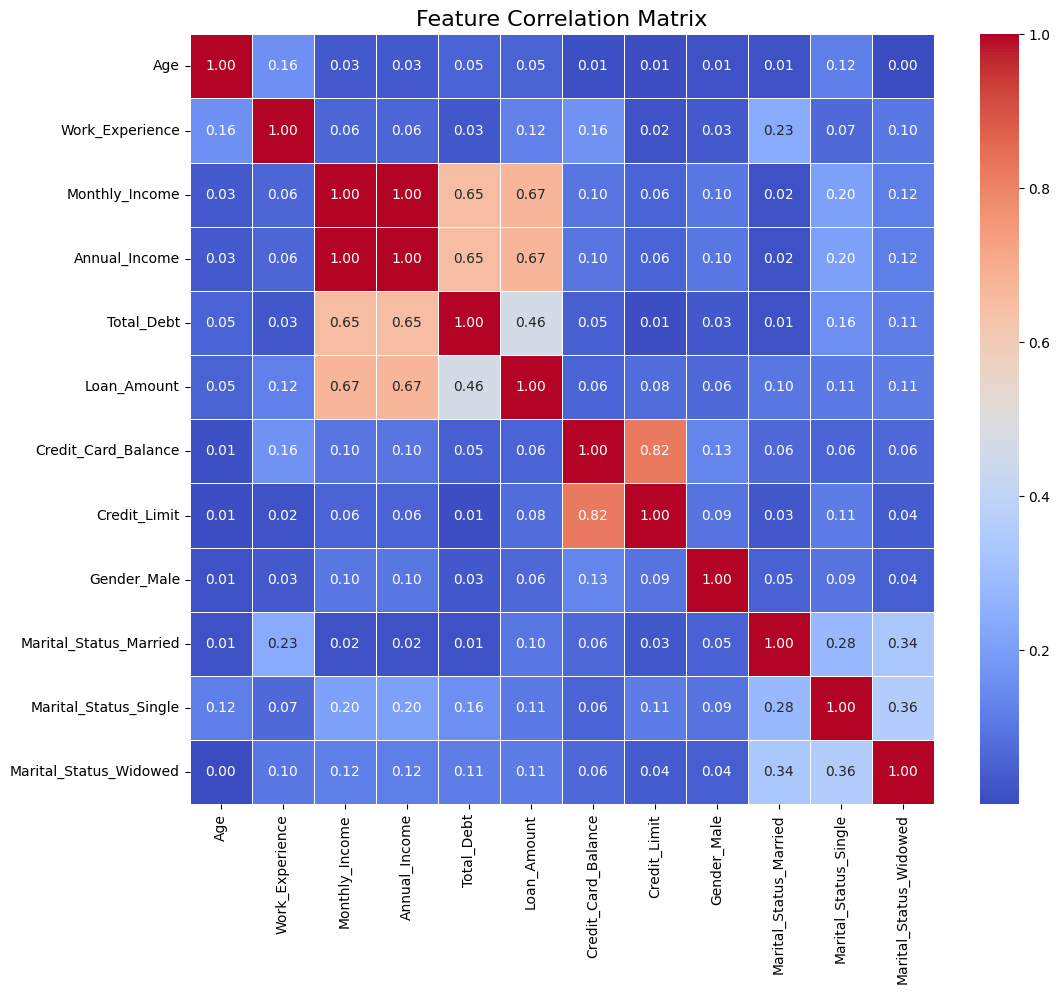

In [7]:
# Create a correlation matrix
corr_matrix = X.corr().abs()
plt.figure(figsize=(12, 10))

# 3. Draw the heatmap using seaborn
sns.heatmap(corr_matrix,       # The data to plot
            annot=True,        # Show the correlation values in the cells
            fmt='.2f',         # Format values to two decimal places
            cmap='coolwarm',   # Use a color map that shows positive (warm) and negative (cool) correlations clearly
            linewidths=.5)     # Add thin lines to separate cells

# 4. Add a title for clarity
plt.title('Feature Correlation Matrix', fontsize=16)

# 5. Display the plot
plt.show()

In [8]:


# Select upper triangle of correlation matrix
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

# Find features with correlation greater than 0.95
to_drop = [column for column in upper.columns if any(upper[column] > 0.8)]
X_corr_filtered = X.drop(columns=to_drop)

print(f"Removed {len(to_drop)} highly correlated features: {to_drop}")
print(f"Selected features after correlation filtering: {X_corr_filtered.columns.tolist()}")



Removed 2 highly correlated features: ['Annual_Income', 'Credit_Limit']
Selected features after correlation filtering: ['Age', 'Work_Experience', 'Monthly_Income', 'Total_Debt', 'Loan_Amount', 'Credit_Card_Balance', 'Gender_Male', 'Marital_Status_Married', 'Marital_Status_Single', 'Marital_Status_Widowed']


In [9]:

# Split data, train, and evaluate the model
X_train_corr, X_test_corr, y_train_corr, y_test_corr = train_test_split(
    X_corr_filtered, y, test_size=0.20, random_state=42
)

model_corr = GaussianNB()
model_corr.fit(X_train_corr, y_train_corr)
y_pred_corr = model_corr.predict(X_test_corr)
accuracy_corr = accuracy_score(y_test_corr, y_pred_corr)

print(f"Accuracy with Correlation-based selection: {accuracy_corr:.2%}\n")



Accuracy with Correlation-based selection: 85.00%



In [10]:

# --- Cell 4: Feature Selection using PCA ---
print("--- Method 2: Feature Selection with PCA ---")

# First, scale the data as PCA is sensitive to feature scales
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply PCA - let's aim to preserve 95% of the variance
pca = PCA(n_components=0.95)
X_pca = pca.fit_transform(X_scaled)

print(f"Original number of features: {X_scaled.shape[1]}")
print(f"PCA reduced the features to {pca.n_components_} principal components.")



--- Method 2: Feature Selection with PCA ---
Original number of features: 12
PCA reduced the features to 9 principal components.


In [11]:

# Split data, train, and evaluate the model
X_train_pca, X_test_pca, y_train_pca, y_test_pca = train_test_split(
    X_pca, y, test_size=0.20, random_state=42
)

model_pca = GaussianNB()
model_pca.fit(X_train_pca, y_train_pca)
y_pred_pca = model_pca.predict(X_test_pca)
accuracy_pca = accuracy_score(y_test_pca, y_pred_pca)

print(f"Accuracy with PCA-based selection: {accuracy_pca:.2%}\n")



Accuracy with PCA-based selection: 90.00%

